# 01 · Dataset exploration and quality control

**Research question:** Do the brain's functional networks reorganise between childhood (3–12 years) and adulthood?

| | Hypothesis |
|---|---|
| **H1** | The pattern of connections between brain regions is different enough to tell children from adults. |
| **H2** | With development, organisation shifts from mostly *local* to more *distributed*: regions in the same network become more tightly linked, and connections between networks become more specialised (Fair et al., 2009; Dosenbach et al., 2010). |
| **H3** | These differences are not just explained by children moving more in the scanner. |

**Data:** Richardson et al. (2018), *Nature Communications*. 155 participants watched the short Pixar film *Partly Cloudy* during fMRI. The data were preprocessed with fMRIPrep and downsampled by nilearn.

**In this notebook:** load the data → check the scans → describe the sample → check head motion → exclude noisy scans → turn each scan into one signal per brain region (saved for notebooks 02–04).

In [1]:
# On Colab: clone the repo and %cd into notebooks/ first (see README)
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from nilearn import plotting

sns.set_theme(style="whitegrid")
PALETTE = {"child": "#E69F00", "adult": "#0072B2"}
DATA_DIR = "../data"
FIG_DIR = "../results/figures"

def save(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

## 1. Load the data
The first run downloads about 900 MB to `~/nilearn_data`. After that it loads from disk.

In [2]:
from src.preprocessing import load_dataset, TR

data, pheno = load_dataset()
print(f"{len(data.func)} participants")
pheno.head()

[fetch_development_fmri] Dataset found in /Users/leenagoyal/nilearn_data/development_fmri
155 participants


,participant_id,Age,AgeGroup,Child_Adult,Gender,Handedness
0,sub-pixar155,26.00,Adult,adult,M,R
1,sub-pixar123,27.06,Adult,adult,F,R
2,sub-pixar124,33.44,Adult,adult,M,R
3,sub-pixar125,31.00,Adult,adult,M,R
4,sub-pixar126,19.00,Adult,adult,F,R


## 2. Look at the scans
We start with a quick look at the raw data, one child and one adult.

Shape (x, y, z, time): (50, 59, 50, 168)
Voxel size (mm): (4.0, 4.0, 4.0)
Scan length: 168 volumes x 2.0 s = 5.6 min


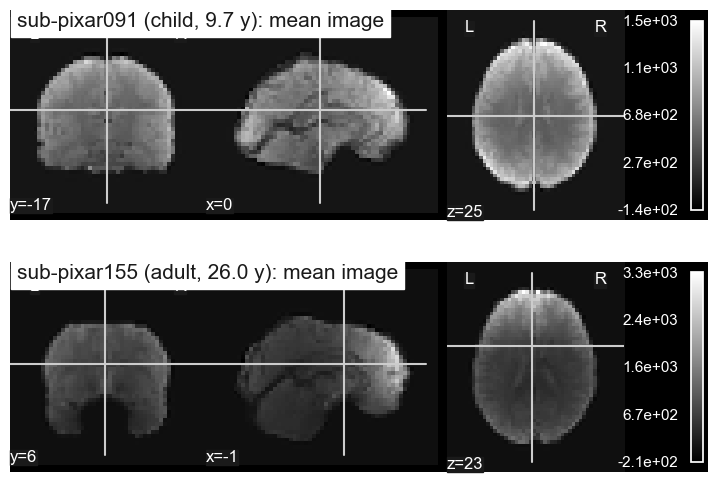

In [3]:
from nilearn import image

child_i = pheno.index[pheno.Child_Adult == "child"][0]
adult_i = pheno.index[pheno.Child_Adult == "adult"][0]

img = image.load_img(data.func[child_i])
print("Shape (x, y, z, time):", img.shape)
print("Voxel size (mm):", tuple(float(v) for v in img.header.get_zooms()[:3]))
print(f"Scan length: {img.shape[3]} volumes x {TR} s = {img.shape[3] * TR / 60:.1f} min")

fig, axes = plt.subplots(2, 1, figsize=(9, 6))
for ax, i in zip(axes, [child_i, adult_i]):
    row = pheno.loc[i]
    plotting.plot_epi(image.mean_img(data.func[i]), axes=ax, display_mode="ortho",
                      title=f"{row.participant_id} ({row.Child_Adult}, {row.Age:.1f} y): mean image")
plt.show()

Each scan is 50 × 59 × 50 voxels (4 mm) × 168 volumes. The file header says TR = 1 s, but the original paper reports **TR = 2 s**, so we use 2 s (≈ 5.6 min per person). Both mean images are aligned to the same standard (MNI) space, with no obvious artefacts.

## 3. Who is in the sample?

             count  mean  std   min   25%   50%   75%   max
Child_Adult                                                
adult         33.0  24.8  5.3  18.0  21.0  23.0  28.0  39.0
child        122.0   6.7  2.3   3.5   4.9   6.0   8.4  12.3


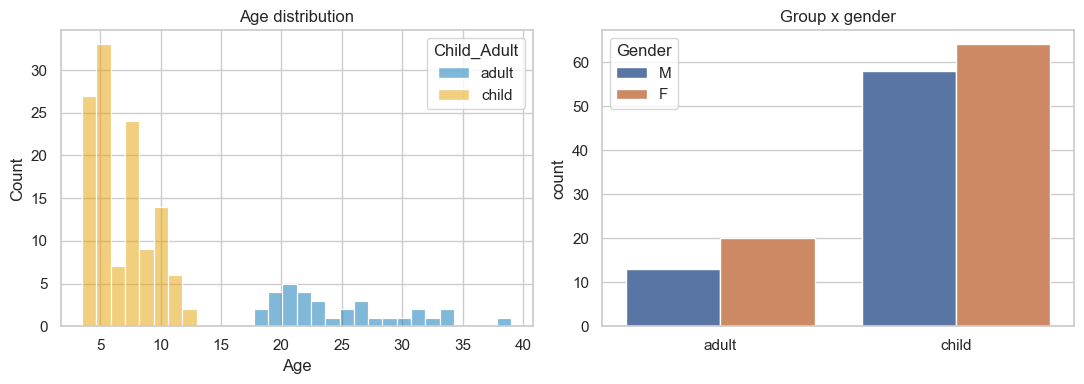

In [4]:
print(pheno.groupby("Child_Adult")["Age"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=pheno, x="Age", hue="Child_Adult", bins=30, palette=PALETTE, ax=axes[0])
axes[0].set_title("Age distribution")
sns.countplot(data=pheno, x="Child_Adult", hue="Gender", ax=axes[1])
axes[1].set(title="Group x gender", xlabel="")
plt.tight_layout(); save("01_sample"); plt.show()

**Insight:** the groups are unbalanced: **122 children** (3.5–12.3 y, mean 6.7) vs. **33 adults** (18–39 y, mean 24.8), roughly 4 : 1. There are **no teenagers** (12–18 y), so we compare two separate age groups and cannot trace a continuous developmental curve. Because of the imbalance, notebook 03 uses *balanced* accuracy.

## 4. Head motion

Motion is the biggest confound in developmental fMRI: a moving head creates false correlations between regions, and children move more.

We use **framewise displacement (FD)** (Power et al., 2012): one number per time point giving how far the head moved since the previous volume, in mm. For each person we keep:
- `mean_fd`: average movement
- `high_motion_frac`: share of volumes with FD > 0.5 mm (a common cut-off for a "big" movement)

In [5]:
from src.preprocessing import compute_motion

pheno = pd.concat([pheno, compute_motion(data.confounds)], axis=1)
pheno[["participant_id", "Age", "Child_Adult", "mean_fd", "high_motion_frac"]].head()

,participant_id,Age,Child_Adult,mean_fd,high_motion_frac
0,sub-pixar155,26.00,adult,0.217095,0.000000
1,sub-pixar123,27.06,adult,0.159037,0.005952
2,sub-pixar124,33.44,adult,0.528821,0.375000
3,sub-pixar125,31.00,adult,0.148315,0.047619
4,sub-pixar126,19.00,adult,0.189773,0.017857


### Do children move more?
FD values are skewed (a few people move a lot), so we use rank-based tests (Mann-Whitney, Spearman) instead of t-tests or Pearson correlation.

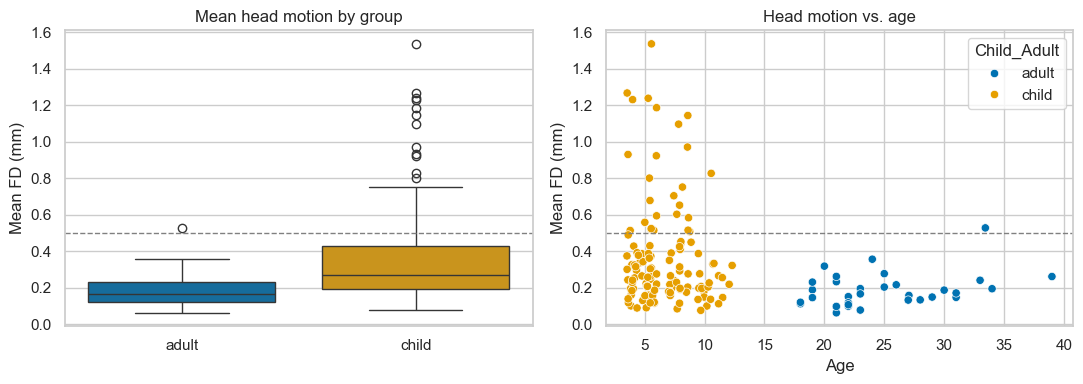

Median FD: 0.272 (children) vs 0.167 (adults)
MannwhitneyuResult(statistic=np.float64(3035.0), pvalue=np.float64(8.00366671909149e-06))
SignificanceResult(statistic=np.float64(-0.28751810826244667), pvalue=np.float64(0.0002861802752955045))


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=pheno, x="Child_Adult", y="mean_fd", hue="Child_Adult", palette=PALETTE, ax=axes[0])
axes[0].set(title="Mean head motion by group", xlabel="", ylabel="Mean FD (mm)")
sns.scatterplot(data=pheno, x="Age", y="mean_fd", hue="Child_Adult", palette=PALETTE, ax=axes[1])
axes[1].set(title="Head motion vs. age", ylabel="Mean FD (mm)")
for ax in axes:
    ax.axhline(0.5, ls="--", c="gray", lw=1)
plt.tight_layout(); save("01_motion"); plt.show()

kids = pheno.mean_fd[pheno.Child_Adult == "child"]
adults = pheno.mean_fd[pheno.Child_Adult == "adult"]
print("Median FD:", round(kids.median(), 3), "(children) vs", round(adults.median(), 3), "(adults)")
print(stats.mannwhitneyu(kids, adults))
print(stats.spearmanr(pheno.Age, pheno.mean_fd))

**Insight:** children moved significantly more than adults (median FD 0.27 vs. 0.17 mm; Mann-Whitney p = 8 × 10⁻⁶; a random child moves more than a random adult 75% of the time), and motion decreases with age (ρ = −0.29). This is the classic problem in developmental fMRI: **age and motion go together**, so any child–adult difference could partly be a motion difference. Motion has to be controlled at every step.

## 5. Exclude scans with too much motion

The rules are fixed **before** looking at any results, so they can't be tuned to get a nicer answer:
- mean FD > 0.5 mm, **or**
- more than 20% of volumes with FD > 0.5 mm

In [7]:
from src.preprocessing import flag_high_motion

pheno["exclude"] = flag_high_motion(pheno)
print(pheno.groupby("Child_Adult")["exclude"].agg(["sum", "count", "mean"]).round(2))

clean = pheno[~pheno.exclude].reset_index(drop=True)
print("Final sample:", clean.Child_Adult.value_counts().to_dict())

             sum  count  mean
Child_Adult                  
adult          1     33  0.03
child         34    122  0.28
Final sample: {'child': 88, 'adult': 32}


### Which children were excluded?
If mostly the youngest children were dropped, the child group would end up older than the original sample, and we would need to report that.

In [8]:
excl = pheno[(pheno.Child_Adult == "child") & pheno.exclude].Age
kept = pheno[(pheno.Child_Adult == "child") & ~pheno.exclude].Age
print("Mean age excluded:", round(excl.mean(), 1), "| kept:", round(kept.mean(), 1))
print(stats.mannwhitneyu(excl, kept))

Mean age excluded: 6.6 | kept: 6.8
MannwhitneyuResult(statistic=np.float64(1519.5), pvalue=np.float64(0.8955049063485728))


### Is there still a motion difference after exclusion?

In [9]:
kids_c = clean.mean_fd[clean.Child_Adult == "child"]
adults_c = clean.mean_fd[clean.Child_Adult == "adult"]
print("Median FD:", round(kids_c.median(), 3), "(children) vs", round(adults_c.median(), 3), "(adults)")
print(stats.mannwhitneyu(kids_c, adults_c))

Median FD: 0.22 (children) vs 0.163 (adults)
MannwhitneyuResult(statistic=np.float64(1927.0), pvalue=np.float64(0.0020908100232093353))


**Insights**
- **34 / 122 children (28%)** but only **1 / 33 adults (3%)** were excluded → final sample **88 children + 32 adults = 120**.
- Excluded and kept children have the same age (6.6 vs. 6.8 y, p = 0.90), so exclusion did **not** make the child group older. However, the kept children are probably calmer than typical children of their age, which is a limitation.
- Even after exclusion, children still move more (median 0.22 vs. 0.16 mm, p = 0.002). So we still need to control for motion later: as a covariate in notebook 02, and with a motion-only baseline and motion regression in notebook 03.

## 6. From brain scans to region signals

Each scan has ~150,000 voxels. We summarise it as **39 brain regions** using the **MSDL atlas** (Varoquaux et al., 2011):
- the regions are grouped into known networks (default mode, attention, visual, motor, language, salience…), so results can be described as *networks* changing;
- it was designed for connectivity analysis, and nilearn's own tutorial uses it on this dataset;
- a finer atlas (e.g. Schaefer-400 → ~80,000 connections) would give far more features than our ~120 participants can support.

39 regions, 17 networks


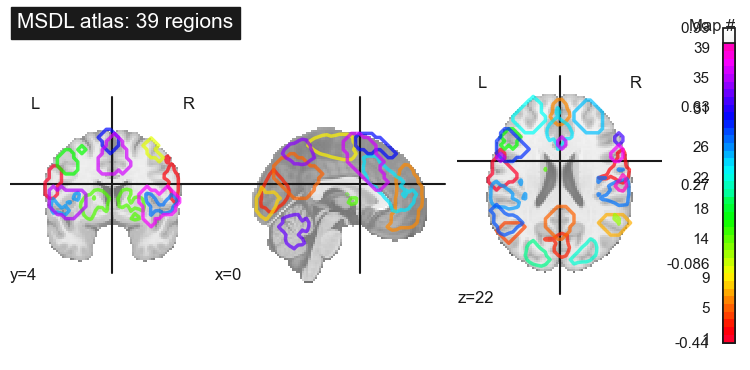

In [10]:
from src.feature_extraction import load_atlas

atlas_maps, labels, networks, coords = load_atlas()
print(len(labels), "regions,", len(set(networks)), "networks")

plotting.plot_prob_atlas(atlas_maps, title="MSDL atlas: 39 regions")
plt.show()

### Noise signals to remove
For each person we regress out:
- **6 head-motion parameters**: movement creates fake signal changes;
- **white matter and CSF**: no neurons there, so their signal is breathing, heartbeat and scanner drift;
- **5 aCompCor components** (Behzadi et al., 2007): the main noise patterns in those tissues.

We do **not** remove the global (whole-brain) signal, because that can create artificial negative correlations.

In [11]:
from src.preprocessing import load_confounds

clean_func = [data.func[i] for i in np.where(~pheno.exclude)[0]]
clean_conf = [data.confounds[i] for i in np.where(~pheno.exclude)[0]]
load_confounds(clean_conf[0]).shape   # (time points, noise signals)

(168, 13)

### Extract one cleaned signal per region
We also band-pass filter to **0.01–0.1 Hz**: the brain fluctuations that matter for connectivity are slow. Below 0.01 Hz is mostly scanner drift, above 0.1 Hz mostly breathing and heartbeat.

This step takes a few minutes, so the result is saved to `data/` and reused.

In [12]:
from src.preprocessing import make_masker, extract_time_series

masker = make_masker(atlas_maps)
time_series = extract_time_series(clean_func, clean_conf, masker,
                                  ids=clean.participant_id.values,
                                  cache_path=f"{DATA_DIR}/time_series_msdl.npz")
clean.to_csv(f"{DATA_DIR}/participants_clean.csv", index=False)
len(time_series), time_series[0].shape

20/120


40/120


60/120


80/120


100/120


120/120


(120, (168, 39))

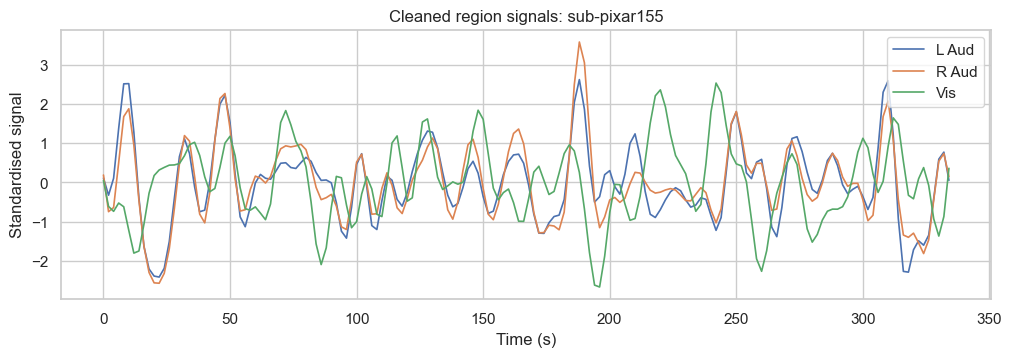

In [13]:
fig, ax = plt.subplots(figsize=(12, 3.5))
t = np.arange(time_series[0].shape[0]) * TR
for r in [0, 1, 20]:
    ax.plot(t, time_series[0][:, r], label=labels[r], lw=1.2)
ax.set(xlabel="Time (s)", ylabel="Standardised signal",
       title=f"Cleaned region signals: {clean.participant_id[0]}")
ax.legend(loc="upper right"); plt.show()

The signals are slow waves around 0. Regions whose lines rise and fall together are **functionally connected**; notebook 02 measures this for every pair of regions.

## Summary

| Step | Result |
|---|---|
| Data | 155 participants, 168 volumes × 2 s each, MNI space |
| Motion | Children move more (p = 8 × 10⁻⁶); motion falls with age |
| Exclusion | 34 children, 1 adult → **120 kept** (88 children, 32 adults) |
| Remaining confound | Children still move slightly more (p = 0.002) |
| Output | `data/time_series_msdl.npz` (120 × 168 × 39) and `data/participants_clean.csv` |

**Next:** notebook 02 turns these signals into connectivity and compares the groups.